### Galaxy multiplets

`GalaxyMultiplets` links galaxies closer than `r_max` in 3D and `r_perp_max` perpendicular to the line of sight, groups linked galaxies into multiplets (pairs, triplets, quadruplets, ...), and cross-correlates each class (singlets included) with the full galaxy sample in $(r_p, \pi)$.

- **Box**: no randoms. Periodic boundaries, fixed line of sight `los`.
- **Cutsky**: pass `randoms_positions`. Cartesian positions with the observer at the origin, midpoint line of sight, Davis-Peebles estimator.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
%config InlineBackend.figure_format = "retina"

from helpers import make_lagrangian_mock

from acm import setup_logging
from acm.estimators.galaxy_clustering.backends.pyrecon import (
    PyreconBackend,  # noqa: F401 - register backend
)
from acm.estimators.galaxy_clustering.multiplets import GalaxyMultiplets

setup_logging()

#### Box

In [2]:
los = "z"
data_positions, boxsize = make_lagrangian_mock(boxsize=500.0, los=los)

# Positions centred on 0 are fine: they are wrapped into [0, boxsize) internally
estimator = GalaxyMultiplets(
    backend="pyrecon",  # We need a backend for the geometry, but no mesh is used
    data_positions=data_positions,
    boxsize=boxsize,
    meshsize=32,
    r_max=7.0,
    r_perp_max=1.05,
    los=los,
)
multiplets = estimator.identify_multiplets()
{n: len(pos) for n, pos in multiplets.items()}

/Users/epaillas/code/cosmoprimo/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuEngine cannot cope with massive neutrinos
  warnings.warn(


[000001.69]  11-12 16:52  LagrangianLinearMock:177 INFO White noise generated.


[000004.78]  11-12 16:52  LagrangianLinearMock:177 INFO Poisson sampling done, total number of objects is 100301.


[000006.20]  11-12 16:52  LagrangianLinearMock:177 INFO Catalog produced. Assigning in cell shift.


[000006.34]  11-12 16:52  acm.utils.backends:108 INFO Loading backend 'pyrecon'


[000006.35]  11-12 16:52  acm.estimators.galaxy_clustering.base:43 INFO Initializing GalaxyMultiplets with PyreconBackend


[000006.36]  11-12 16:52  acm.estimators.galaxy_clustering.multiplets:135 INFO Finding pairs with r_max=7.0, r_perp_max=1.05


[000006.76]  11-12 16:52  acm.estimators.galaxy_clustering.multiplets:152 INFO 33.97% of galaxies are in multiplets. Counts: singlet=66227, pair=7497, triplet=2094, quadruplet=890


{1: 66227, 2: 7497, 3: 2094, 4: 890}

In [3]:
edges = (np.linspace(2.0, 30.0, 14), np.linspace(-60, 60, 121))  # (rp, pi)
result = estimator.compute(edges, nthreads=4)
result  # one Count2Correlation per multiplet class

[000006.77]  11-12 16:52  acm.estimators.galaxy_clustering.multiplets:262 INFO Computing singlet cross-correlation (66227 objects)


[000006.77]  11-12 16:52  TwoPointCorrelationFunction:304 INFO Using estimator <class 'pycorr.twopoint_estimator.NaturalTwoPointEstimator'>.


[000006.77]  11-12 16:52  TwoPointCorrelationFunction:343 INFO Running cross-correlation.


[000006.77]  11-12 16:52  TwoPointCorrelationFunction:373 INFO Computing two-point counts D1D2.


[000007.05]  11-12 16:52  numexpr.utils:151 INFO Note: NumExpr detected 18 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 16.


[000007.05]  11-12 16:52  numexpr.utils:164 INFO NumExpr defaulting to 16 threads.


... (17 outputs left out)

[000007.62]  11-12 16:52  TwoPointCorrelationFunction:373 INFO Computing two-point counts D1D2.


[000007.64]  11-12 16:52  TwoPointCorrelationFunction:364 INFO Analytically computing two-point counts R1R2.


[000007.64]  11-12 16:52  TwoPointCorrelationFunction:408 INFO Correlation function computed in elapsed time 0.02 s.


ObservableTree(labels=[{'multiplets': 'singlet'}, {'multiplets': 'pair'}, {'multiplets': 'triplet'}, {'multiplets': 'quadruplet'}], size=6240)

[000007.68]  11-12 16:52  acm.estimators.galaxy_clustering.base:104 INFO Writing GalaxyMultiplets estimator to multiplets_box.h5.


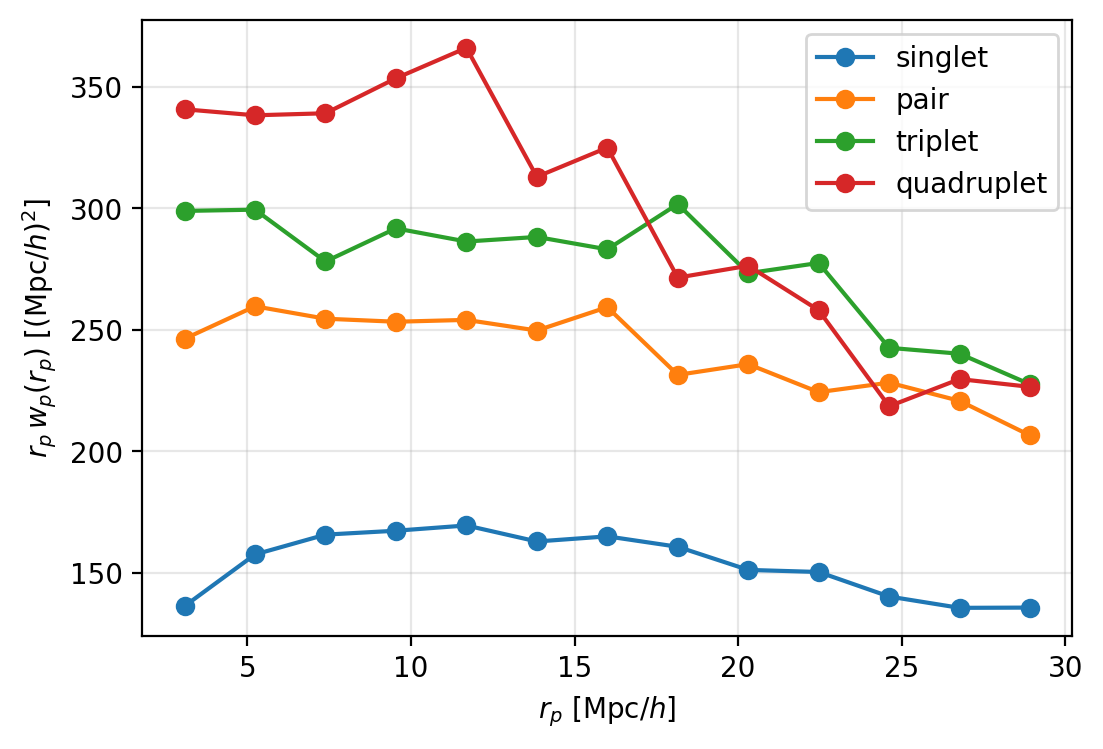

In [4]:
# Save, then load projected onto wp(rp) and plot
estimator.save(result, "multiplets_box.h5", overwrite=True)
wp = GalaxyMultiplets.load("multiplets_box.h5", project=True)

fig, ax = GalaxyMultiplets.plot(wp, marker="o")
ax.grid(True, alpha=0.3)

In [5]:
# Access a single class - see lsstypes docs
pair = wp.get(multiplets="pair")
pair.coords("rp"), pair.value()

(array([ 3.07692308,  5.23076923,  7.38461538,  9.53846154, 11.69230769,
        13.84615385, 16.        , 18.15384615, 20.30769231, 22.46153846,
        24.61538462, 26.76923077, 28.92307692]),
 array([80.0622374 , 49.65197325, 34.47928712, 26.56314724, 21.73472186,
        18.03764757, 16.21037221, 12.75227622, 11.6167095 ,  9.99018066,
         9.27456174,  8.24873021,  7.14252398]))

#### Cutsky

Positions are Cartesian with the observer at the origin, for data and randoms alike (convert RA, DEC, distance upstream). Here we place the box mock at 1000 Mpc/$h$ and cut an angular and radial window.

> Saving cutsky results requires Davis-Peebles support in lsstypes ([adematti/lsstypes#6](https://github.com/adematti/lsstypes/issues/6)). Until then `compute` raises a `NotImplementedError` in cutsky mode; multiplet identification works.

In [6]:
rng = np.random.default_rng(1)
center = np.array([1000.0, 0.0, 0.0])


def in_window(xyz):
    dist = np.linalg.norm(xyz, axis=1)
    ra = np.rad2deg(np.arctan2(xyz[:, 1], xyz[:, 0]))
    dec = np.rad2deg(np.arcsin(xyz[:, 2] / dist))
    return (np.abs(ra) < 12) & (np.abs(dec) < 10) & (dist > 850) & (dist < 1150)


xyz = data_positions + center
cutsky_positions = xyz[in_window(xyz)]
randoms = rng.uniform(-250, 250, size=(2_000_000, 3)) + center
randoms = randoms[in_window(randoms)][: 5 * len(cutsky_positions)]
len(cutsky_positions), len(randoms)

(33904, 169520)

In [7]:
estimator = GalaxyMultiplets(
    backend="pyrecon",
    data_positions=cutsky_positions,
    randoms_positions=randoms,  # randoms -> cutsky mode
    boxsize=800.0,  # backend box enclosing the survey
    boxcenter=center,
    meshsize=32,
)
multiplets = estimator.identify_multiplets()
{n: len(pos) for n, pos in multiplets.items()}

[000008.03]  11-12 16:52  acm.utils.backends:108 INFO Loading backend 'pyrecon'


[000008.05]  11-12 16:52  acm.estimators.galaxy_clustering.base:43 INFO Initializing GalaxyMultiplets with PyreconBackend


[000008.05]  11-12 16:52  acm.estimators.galaxy_clustering.multiplets:135 INFO Finding pairs with r_max=7.0, r_perp_max=1.05


[000008.11]  11-12 16:52  acm.estimators.galaxy_clustering.multiplets:152 INFO 28.99% of galaxies are in multiplets. Counts: singlet=24074, pair=2558, triplet=628, quadruplet=233


{1: 24074, 2: 2558, 3: 628, 4: 233}

In [8]:
try:
    result = estimator.compute(edges, nthreads=4)
    fig, ax = GalaxyMultiplets.plot(result, marker="o")
except NotImplementedError as exc:
    print(exc)

[000008.11]  11-12 16:52  acm.estimators.galaxy_clustering.multiplets:262 INFO Computing singlet cross-correlation (24074 objects)


[000008.12]  11-12 16:52  TwoPointCorrelationFunction:304 INFO Using estimator <class 'pycorr.twopoint_estimator.DavisPeeblesTwoPointEstimator'>.


[000008.12]  11-12 16:52  TwoPointCorrelationFunction:343 INFO Running cross-correlation.


[000008.12]  11-12 16:52  TwoPointCorrelationFunction:373 INFO Computing two-point counts D1D2.


[000008.20]  11-12 16:53  TwoPointCorrelationFunction:373 INFO Computing two-point counts D1R2.


[000008.46]  11-12 16:53  TwoPointCorrelationFunction:408 INFO Correlation function computed in elapsed time 0.35 s.


Cutsky multiplets use the Davis-Peebles estimator, which the installed lsstypes does not support yet. See https://github.com/adematti/lsstypes/issues/6.
